# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:** RTX 4060 Laptop 8 GB, CUDA; финальный запуск с FAST_MODE=False. GymCLASS v1, [источник](https://universe.roboflow.com/ternnnnnnnnnn/gymclass/dataset/1), CC BY 4.0. Основная часть 1–5 и бонусы 6.3, 6.5 выполнены; 6.1, 6.2, 6.4 не выбирал. Использованы готовые функции из условия и [документация Ultralytics](https://docs.ultralytics.com). При подготовке использовался ChatGPT. Версии и параметры запуска сохранены в artifacts.

In [1]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.20'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
torch.set_num_threads(4)
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.20, torch 2.11.0+cu128, device: NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.3', '6.5'}     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
WEIGHTS = 'yolo26n.pt'
model_coco = YOLO(WEIGHTS)
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
MODEL_INFO = dict(ultralytics=ultralytics.__version__, weights=weights_path.name,
                  sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
                  size_mb=weights_path.stat().st_size / 1024**2,
                  params=sum(p.numel() for p in model_coco.model.parameters()),
                  n_classes_coco=len(model_coco.names), input_size=IMGSZ, latency_runs=15)
dummy = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)
for _ in range(3):
    model_coco.predict(dummy, imgsz=IMGSZ, device=DEVICE, verbose=False)
latencies = []
for _ in range(15):
    if torch.cuda.is_available(): torch.cuda.synchronize()
    started = time.perf_counter()
    model_coco.predict(dummy, imgsz=IMGSZ, device=DEVICE, verbose=False)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    latencies.append((time.perf_counter() - started) * 1000)
MODEL_INFO['latency_ms'] = float(np.mean(latencies))
MODEL_INFO['latency_std_ms'] = float(np.std(latencies))
print(MODEL_INFO)

{'ultralytics': '8.4.20', 'weights': 'yolo26n.pt', 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef', 'size_mb': 5.287602424621582, 'params': 2572280, 'n_classes_coco': 80, 'input_size': 640, 'latency_runs': 15, 'latency_ms': 22.060413338476792, 'latency_std_ms': 2.0471548645040736}


In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.20',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.287602424621582,
 'params': 2572280,
 'n_classes_coco': 80,
 'input_size': 640,
 'latency_runs': 15,
 'latency_ms': 22.060413338476792,
 'latency_std_ms': 2.0471548645040736}

**Ответ:** Взял nano, потому что здесь всего 360 обучающих картинок и хочется успеть проверить не только обучение, но и абляцию. В [таблице YOLO26](https://docs.ultralytics.com/models/yolo26/) у n против s: 2.4 против 9.5 млн параметров после fusion, COCO mAP50-95 40.9 против 48.6 (end-to-end: 40.1 против 47.8), T4 TensorRT 1.7 против 2.5 мс; s точнее на COCO, но это не обещание такого же выигрыша на GymCLASS. У моего полного checkpoint до fusion 2,572,280 параметров и 22.06 ± 2.05 мс на RTX 4060: измеряю весь predict после прогрева, поэтому напрямую сравнивать с TensorRT нельзя. Код и веса распространяются по [AGPL-3.0](https://www.ultralytics.com/license): нужно сохранять лицензию и уведомления, а при распространении производной работы и предоставлении её пользователям по сети выполнять требования о доступе к соответствующему исходному коду; для закрытых продуктов Ultralytics предлагает отдельную Enterprise-лицензию.

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [6]:
def params_by_block(det_model):
    # Layers follow the YAML: backbone, neck, then Detect.
    layers = det_model.model
    n_backbone = len(det_model.yaml['backbone'])
    return {
        'backbone': sum(p.numel() for layer in layers[:n_backbone] for p in layer.parameters()),
        'neck': sum(p.numel() for layer in layers[n_backbone:-1] for p in layer.parameters()),
        'head': sum(p.numel() for p in layers[-1].parameters()),
    }


def head_inputs_and_output(det_model, imgsz=640):
    feat_shapes = []

    def capture_inputs(module, args):
        # Capture before Detect can replace elements in its input list.
        feat_shapes.extend(tuple(feature.shape) for feature in args[0])

    parameter = next(det_model.parameters(), None)
    if parameter is None:
        parameter = next(det_model.buffers(), None)
    device = parameter.device if parameter is not None else torch.device('cpu')
    dtype = parameter.dtype if parameter is not None and parameter.is_floating_point() else torch.float32
    training_states = [(module, module.training) for module in det_model.modules()]
    handle = det_model.model[-1].register_forward_pre_hook(capture_inputs)
    try:
        det_model.eval()
        with torch.no_grad():
            output = det_model(torch.zeros(1, 3, imgsz, imgsz, device=device, dtype=dtype))
    finally:
        handle.remove()
        for module, was_training in training_states:
            module.training = was_training
    return feat_shapes, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [7]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [8]:
print(shapes(out))
print('end2end:', arch.end2end, 'reg_max:', arch.model[-1].reg_max)

[(1, 300, 6), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]
end2end: True reg_max: 1


**Ответ:** Backbone извлекает признаки картинки, neck смешивает грубые и детальные признаки сверху вниз и обратно, а Detect получает три масштаба: 80×80, 40×40 и 20×20 при входе 640. Отсюда 8400 = 80² + 40² + 20² возможных позиций; в каждой голова предсказывает четыре координатных значения и оценки классов, а не выбирает заранее заданный прямоугольник-якорь — поэтому anchor-free. В нашем checkpoint до fusion на backbone приходится 1 365 472 параметра (53%), neck — 897 152 (35%), head — 309 656 (12%). При обучении one2many допускает несколько положительных предсказаний на объект и даёт более плотный сигнал, one2one учится выдавать один; в проверенной версии 8.4.20 end-to-end использует one2one и выбирает готовые детекции без отдельного NMS, выход имеет форму (1, 300, 6), где 6 — бокс, уверенность и класс. Здесь reg_max=1, распределённой DFL-регрессии нет; устройство головы проверил по [коду версии 8.4.20](https://github.com/ultralytics/ultralytics/blob/v8.4.20/ultralytics/nn/modules/head.py), потому что текущая документация уже описывает и более новые дефолты. Формы выше относятся к исходной COCO-модели с 80 классами; при дообучении выход классификации перестраивается под наши 12 классов.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [9]:
import zipfile
import io
import requests

DATASET_URL = 'https://universe.roboflow.com/ternnnnnnnnnn/gymclass/dataset/1'
DATASET_NAME = 'GymCLASS v1; ' + DATASET_URL + '; CC BY 4.0'
RAW_ROOT = DATA_ROOT / 'gymclass'
archive = DATA_ROOT / 'GymCLASS.v1i.coco.zip'

def ensure_gymclass():
    if all((RAW_ROOT / split / '_annotations.coco.json').exists() for split in ['train', 'valid', 'test']):
        return
    DATA_ROOT.mkdir(exist_ok=True)
    if not archive.exists():
        key = os.environ.get('ROBOFLOW_API_KEY')
        if not key:
            raise RuntimeError('Скачайте COCO ZIP по DATASET_URL в data/GymCLASS.v1i.coco.zip или задайте ROBOFLOW_API_KEY. Ключ в notebook не записывайте.')
        # Официальный REST-экспорт; ключ передаётся в заголовке и не попадает в outputs.
        response = requests.get('https://api.roboflow.com/ternnnnnnnnnn/gymclass/1/coco',
                                headers={'Authorization': 'Bearer ' + key}, timeout=120)
        if response.status_code != 200:
            raise RuntimeError(f'Roboflow export failed, HTTP {response.status_code}')
        link = response.json().get('export', {}).get('link')
        if not link:
            raise RuntimeError('Roboflow не вернул ссылку экспорта; скачайте ZIP через страницу датасета.')
        downloaded = requests.get(link, timeout=120)
        if downloaded.status_code != 200:
            raise RuntimeError(f'Dataset download failed, HTTP {downloaded.status_code}')
        archive.write_bytes(downloaded.content)
    with zipfile.ZipFile(archive) as z:
        if z.testzip() is not None:
            raise ValueError('Повреждён архив датасета')
        for split in ['train', 'valid', 'test']:
            target = RAW_ROOT / split
            target.mkdir(parents=True, exist_ok=True)
            doc = json.loads(z.read(split + '/_annotations.coco.json'))
            for image in doc['images']:
                original = image['file_name']
                suffix = Path(original).suffix.lower()
                if suffix not in {'.jpg', '.jpeg', '.png', '.webp'}:
                    raise ValueError('Unexpected image suffix')
                # Короткие имена обходят лимит пути Windows, image_id и боксы сохраняются.
                name = f"{int(image['id']):06d}{suffix}"
                (target / name).write_bytes(z.read(split + '/' + original))
                image['original_file_name'] = original
                image['file_name'] = name
            (target / '_annotations.coco.json').write_text(json.dumps(doc), encoding='utf-8')
        for name in ['README.dataset.txt', 'README.roboflow.txt']:
            (RAW_ROOT / name).write_bytes(z.read(name))

ensure_gymclass()
documents = {s: json.loads((RAW_ROOT / raw / '_annotations.coco.json').read_text(encoding='utf-8'))
             for s, raw in [('train', 'train'), ('val', 'valid'), ('test', 'test')]}
train_ids = {a['category_id'] for a in documents['train']['annotations']}
category_names = {c['id']: c['name'] for c in documents['train']['categories']}
category_ids = sorted(train_ids)
CLASSES = [category_names[i] for i in category_ids]
category_map = {old: new for new, old in enumerate(category_ids)}
records, CLEANING, split_hashes = {}, {}, {}
for split, doc in documents.items():
    source_split = 'valid' if split == 'val' else split
    ann_by_image = {}
    for a in doc['annotations']:
        ann_by_image.setdefault(a['image_id'], []).append(a)
    records[split], clipped, removed = [], 0, 0
    split_hashes[split] = set()
    for image in doc['images']:
        path = RAW_ROOT / source_split / image['file_name']
        with Image.open(path) as img:
            assert img.size == (image['width'], image['height'])
            split_hashes[split].add(hashlib.sha256(img.convert('RGB').tobytes()).hexdigest())
        boxes, labels = [], []
        for a in ann_by_image.get(image['id'], []):
            x, y, w, h = a['bbox']
            box = np.array([x, y, x+w, y+h], dtype=np.float64)
            clean = np.clip(box, [0, 0, 0, 0], [image['width'], image['height'], image['width'], image['height']])
            clipped += int(not np.array_equal(box, clean))
            if clean[2] <= clean[0] or clean[3] <= clean[1]:
                removed += 1
                continue
            boxes.append(clean)
            labels.append(category_map[a['category_id']])
        records[split].append(dict(image=path, width=image['width'], height=image['height'],
                                   boxes=np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
                                   labels=np.asarray(labels, dtype=np.int64)))
    CLEANING[split] = dict(clipped=clipped, removed=removed)
EXACT_DUPLICATES = {a+' / '+b: len(split_hashes[a] & split_hashes[b])
                    for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]}
print('Классы:', CLASSES)
print('Очистка:', CLEANING, 'точные совпадения между сплитами:', EXACT_DUPLICATES)

Классы: ['barbell', 'cablemachine', 'dumbbell', 'elliptical', 'kettlebell', 'legpress', 'smithmachine', 'stationarybike', 'swissball', 'treadmill', 'weightplate', 'yogamat']
Очистка: {'train': {'clipped': 4, 'removed': 0}, 'val': {'clipped': 1, 'removed': 0}, 'test': {'clipped': 1, 'removed': 0}} точные совпадения между сплитами: {'train / val': 0, 'train / test': 0, 'val / test': 0}


In [10]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 360, 'val': 120, 'test': 120}

train {'images': 360, 'objects': 396, 'counts': [31, 30, 44, 30, 38, 30, 31, 34, 30, 31, 37, 30], 'objects_per_image': 1.1, 'median_box_area': 0.5305574205186632}
val {'images': 120, 'objects': 134, 'counts': [10, 10, 16, 11, 13, 10, 10, 10, 10, 11, 13, 10], 'objects_per_image': 1.1166666666666667, 'median_box_area': 0.5370966593424479}
test {'images': 120, 'objects': 139, 'counts': [10, 10, 19, 10, 12, 12, 10, 11, 10, 10, 15, 10], 'objects_per_image': 1.1583333333333334, 'median_box_area': 0.48559570312500006}


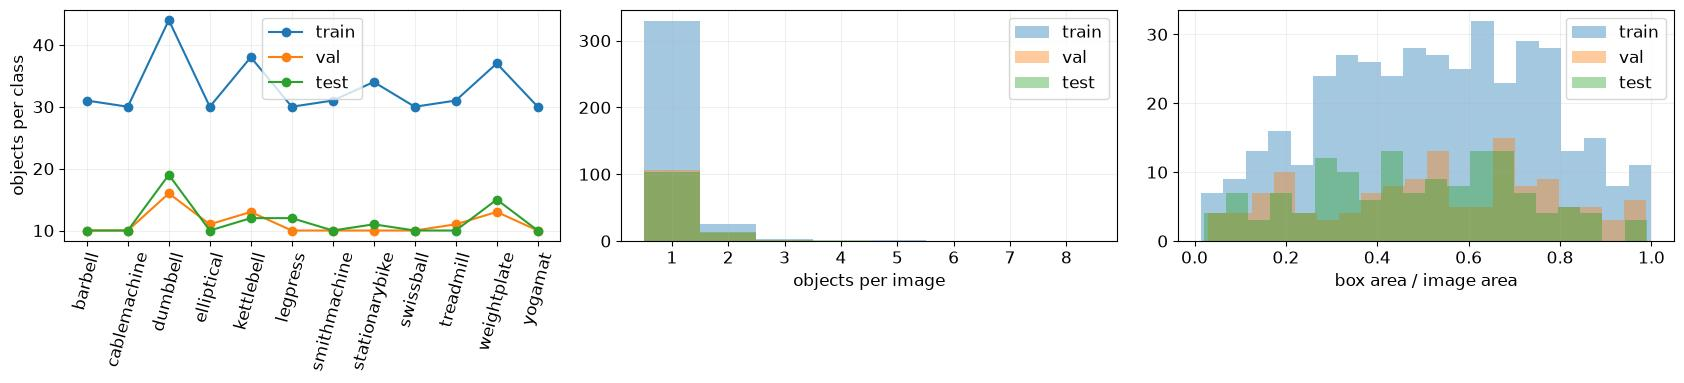

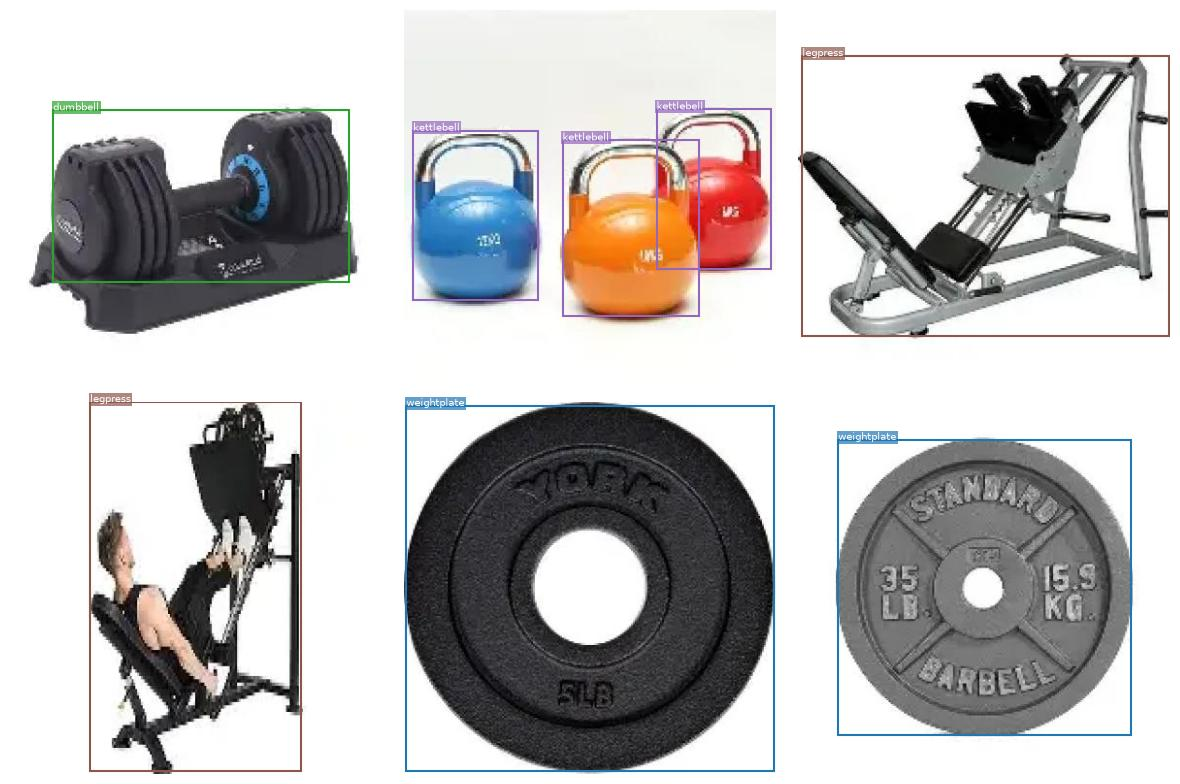

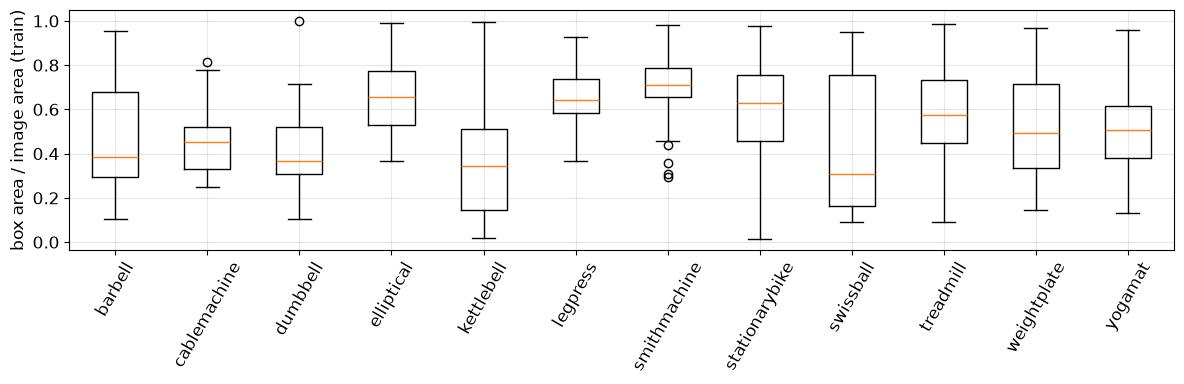

In [11]:
DATA_STATS = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for split, recs in records.items():
    counts = np.bincount(np.concatenate([r['labels'] for r in recs]), minlength=len(CLASSES))
    areas = np.concatenate([np.prod((r['boxes'][:, 2:] - r['boxes'][:, :2]) / [r['width'], r['height']], axis=1) for r in recs])
    DATA_STATS[split] = dict(images=len(recs), objects=int(counts.sum()), counts=counts.tolist(),
                             objects_per_image=float(counts.sum()/len(recs)), median_box_area=float(np.median(areas)))
    axes[0].plot(range(len(CLASSES)), counts, 'o-', label=split)
    axes[1].hist([len(r['labels']) for r in recs], bins=np.arange(0.5, 9.5), alpha=.4, label=split)
    axes[2].hist(areas, bins=20, alpha=.4, label=split)
    print(split, DATA_STATS[split])
axes[0].set_xticks(range(len(CLASSES)), CLASSES, rotation=75)
axes[0].set_ylabel('objects per class')
axes[1].set_xlabel('objects per image')
axes[2].set_xlabel('box area / image area')
for ax in axes:
    ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, r in zip(axes.flat, records['train'][:6]):
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES)
plt.tight_layout(); plt.show()

class_areas = [[] for _ in CLASSES]
for r in records['train']:
    areas = np.prod((r['boxes'][:,2:]-r['boxes'][:,:2])/[r['width'],r['height']],axis=1)
    for label,area in zip(r['labels'],areas): class_areas[int(label)].append(float(area))
fig,ax=plt.subplots(figsize=(12,4))
ax.boxplot(class_areas,tick_labels=CLASSES,showfliers=True)
ax.tick_params(axis='x',rotation=60); ax.set_ylabel('box area / image area (train)')
ax.grid(alpha=.3); plt.tight_layout(); plt.show()

**Ответ:** Взял [GymCLASS v1](https://universe.roboflow.com/ternnnnnnnnnn/gymclass/dataset/1), лицензия CC BY 4.0: 600 изображений, 12 классов оборудования, готовые сплиты train/val/test = 360/120/120. В train по 30–44 объекта на класс, всего объектов 396/134/139, то есть около 1.1 на картинку; медианный бокс занимает примерно 49–54% площади, поэтому это в основном крупные одиночные предметы, а не плотные сцены с мелкими объектами. Обрезал по границам изображения 4/1/1 бокса, пустых после обрезки не было; неиспользуемую общую категорию Gym-Equipment убрал из списка классов. По изображениям это в основном каталожные фото, часто на белом фоне: точных пиксельных совпадений между сплитами нет, но похожие товарные снимки возможны, поэтому результат ещё не доказывает работу на видео из реального зала.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [12]:
def to_yolo(boxes, labels, width, height):
    if width <= 0 or height <= 0:
        raise ValueError('Image dimensions must be positive')
    boxes = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    labels = np.asarray(labels, dtype=np.int64).reshape(-1)
    if len(boxes) != len(labels):
        raise ValueError('Each box must have one label')
    # Dataset cleaning removes invalid boxes; clipping handles image boundaries.
    normalized = np.clip(boxes / [width, height, width, height], 0.0, 1.0)
    centers = (normalized[:, :2] + normalized[:, 2:]) / 2
    sizes = normalized[:, 2:] - normalized[:, :2]
    return '\n'.join(
        f'{int(label)} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}'
        for label, (cx, cy), (w, h) in zip(labels, centers, sizes)
    )


def from_yolo(text, width, height):
    if width <= 0 or height <= 0:
        raise ValueError('Image dimensions must be positive')
    boxes, labels = [], []
    for line in text.splitlines():
        if not line.strip():
            continue
        label, cx, cy, w, h = line.split()
        cx, cy, w, h = map(float, (cx, cy, w, h))
        boxes.append([(cx - w / 2) * width, (cy - h / 2) * height,
                      (cx + w / 2) * width, (cy + h / 2) * height])
        labels.append(int(label))
    return np.asarray(boxes, dtype=np.float32).reshape(-1, 4), np.asarray(labels, dtype=np.int64)

In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    image_dir, label_dir = YOLO_ROOT / 'images' / split, YOLO_ROOT / 'labels' / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    for i, r in enumerate(recs):
        name = f'{i:06d}'
        shutil.copy2(r['image'], image_dir / (name + Path(r['image']).suffix.lower()))
        (label_dir / (name + '.txt')).write_text(to_yolo(r['boxes'], r['labels'], r['width'], r['height']), encoding='utf-8')


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
assert YOLO_ROOT.resolve() == (Path.cwd() / 'data' / 'yolo').resolve()
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: C:/Users/arseni/all/code/deepLearning/labs/lab2/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: barbell
  1: cablemachine
  2: dumbbell
  3: elliptical
  4: kettlebell
  5: legpress
  6: smithmachine
  7: stationarybike
  8: swissball
  9: treadmill
  10: weightplate
  11: yogamat



Максимальная ошибка round-trip, px: 0.0002593994140625


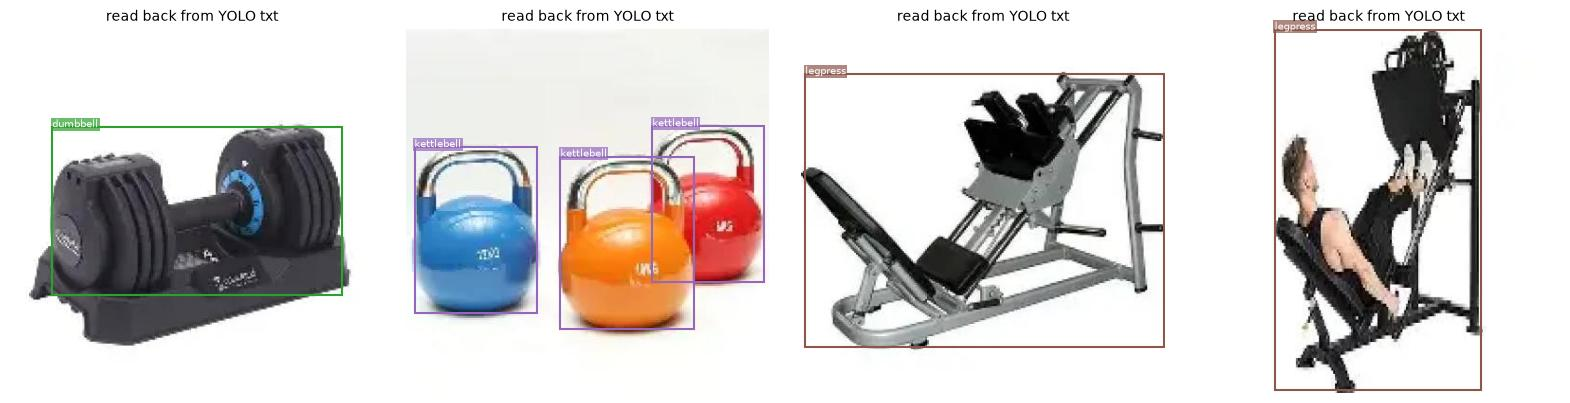

In [15]:
roundtrip_errors = []
for split, recs in splits.items():
    for i, r in enumerate(recs):
        text = (YOLO_ROOT / 'labels' / split / f'{i:06d}.txt').read_text(encoding='utf-8')
        boxes, labels = from_yolo(text, r['width'], r['height'])
        assert np.array_equal(labels, r['labels'])
        assert np.allclose(boxes, r['boxes'], atol=.002)
        roundtrip_errors.append(float(np.max(np.abs(boxes-r['boxes']))) if len(boxes) else 0.)
print('Максимальная ошибка round-trip, px:', max(roundtrip_errors))
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, (ax, r) in enumerate(zip(axes, splits['train'][:4])):
    text = (YOLO_ROOT / 'labels' / 'train' / f'{i:06d}.txt').read_text(encoding='utf-8')
    b, l = from_yolo(text, r['width'], r['height'])
    draw_boxes(ax, Image.open(r['image']), b, l, CLASSES, title='read back from YOLO txt')
plt.tight_layout(); plt.show()

**Ответ:** На всём экспорте максимальная ошибка восстановления координат составила 0.0002594 пикселя — это округление до шести знаков, а не заметный сдвиг бокса. Тест туда-обратно проверяет согласованность двух функций и сохранение классов, но если обе одинаково неправильно понимают координаты, они могут успешно восстановить собственную ошибку. Поэтому отдельно посмотрел боксы поверх картинок: так видны перепутанные оси, неверные размеры изображения, смещение и несоответствие подписи самому предмету; правильность исходной разметки один round-trip не доказывает.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

Совпадающие имена классов COCO: {} mAP50: 0.0


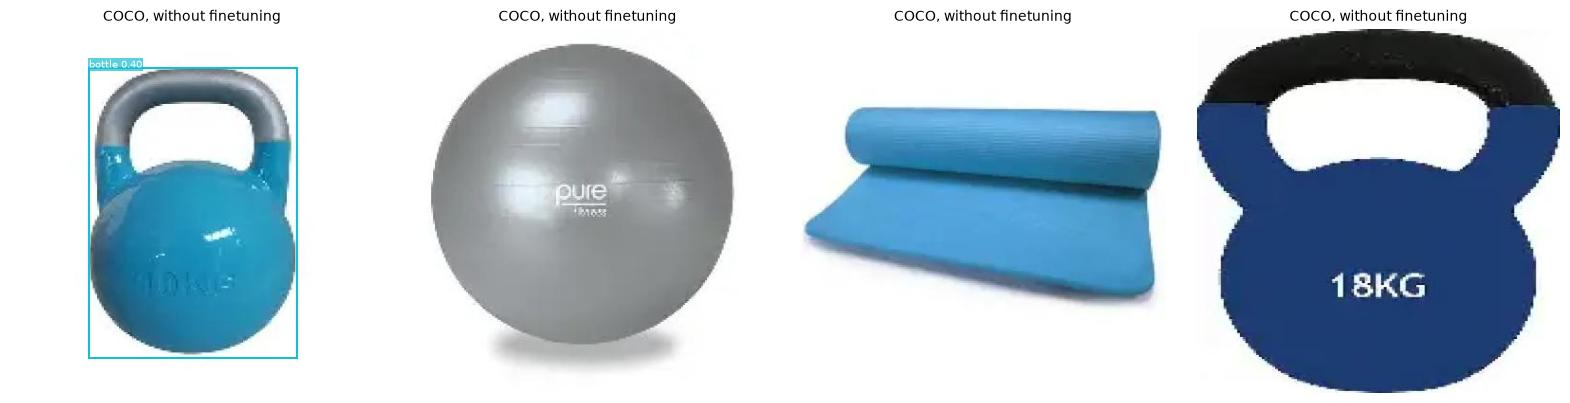

In [16]:
started = time.perf_counter()
coco_preds_raw = predict_records(model_coco, records[FINAL_SPLIT])
coco_names = model_coco.names
COCO_CLASS_MAP = {i: CLASSES.index(name) for i, name in coco_names.items() if name in CLASSES}
coco_preds = []
for p in coco_preds_raw:
    keep = np.array([int(label) in COCO_CLASS_MAP for label in p['labels']], dtype=bool)
    coco_preds.append(dict(boxes=p['boxes'][keep], scores=p['scores'][keep],
                           labels=np.array([COCO_CLASS_MAP[int(c)] for c in p['labels'][keep]], dtype=np.int64)))
coco_map50, coco_aps = evaluate_map50(coco_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['coco_baseline'] = time.perf_counter() - started
print('Совпадающие имена классов COCO:', COCO_CLASS_MAP, 'mAP50:', coco_map50)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, r, p in zip(axes, records[FINAL_SPLIT][:4], coco_preds_raw[:4]):
    keep = p['scores'] >= .25
    draw_boxes(ax, Image.open(r['image']), p['boxes'][keep], p['labels'][keep], coco_names, p['scores'][keep], title='COCO, without finetuning')
plt.tight_layout(); plt.show()

In [17]:
def simple_features(image):
    image = image.convert('RGB')
    array = np.asarray(image.resize((32, 32)), dtype=np.float32) / 255
    mask = array.min(2) < .90
    occupancy = mask.reshape(4, 8, 4, 8).mean((1, 3)).ravel()
    return np.r_[occupancy, array.mean((0, 1)), array.std((0, 1)),
                 image.width/max(1, image.height), mask.mean()]


def heuristic_detect(image_path):
    image = Image.open(image_path).convert('RGB')
    array = np.asarray(image)
    mask = array.min(2) < 230
    mask = ndimage.binary_closing(mask, iterations=2)
    components, n = ndimage.label(mask)
    objects = ndimage.find_objects(components)
    proposals = []
    for k, slices in enumerate(objects, 1):
        if slices is None: continue
        area = int((components[slices] == k).sum())
        if area < image.width*image.height*.005: continue
        ys, xs = slices
        proposals.append((area, [xs.start, ys.start, xs.stop, ys.stop]))
    proposals = sorted(proposals, reverse=True)[:3]
    boxes, labels, scores = [], [], []
    for area, box in proposals:
        feature = (simple_features(image.crop(box)) - FEATURE_MEAN) / FEATURE_SCALE
        distances = ((CENTROIDS - feature)**2).mean(1)
        label = int(np.argmin(distances))
        boxes.append(box); labels.append(label); scores.append(1/(1+float(np.sqrt(distances[label]))))
    return dict(boxes=np.array(boxes, dtype=np.float32).reshape(-1,4),
                labels=np.array(labels,dtype=np.int64), scores=np.array(scores,dtype=np.float32))

In [18]:
# Параметры признаков и центроиды оцениваем только по train.
features, targets = [], []
for r in train_recs:
    with Image.open(r['image']) as image:
        for box, label in zip(r['boxes'], r['labels']):
            features.append(simple_features(image.crop(tuple(map(float, box)))))
            targets.append(int(label))
features, targets = np.stack(features), np.asarray(targets)
FEATURE_MEAN, FEATURE_SCALE = features.mean(0), features.std(0).clip(.1)
features = (features-FEATURE_MEAN)/FEATURE_SCALE
CENTROIDS = np.stack([features[targets==i].mean(0) if np.any(targets==i) else np.full(features.shape[1],1e3)
                      for i in range(len(CLASSES))])
print('Объектов для бейзлайна:', len(features), 'число признаков:', features.shape[1])

Объектов для бейзлайна: 396 число признаков: 24


In [19]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.21834321225469552,
 'heuristic_ap50_per_class': {'barbell': 0.05,
  'cablemachine': 0.38,
  'dumbbell': 0.03508771929824561,
  'elliptical': 0.0,
  'kettlebell': 0.05357142857142857,
  'legpress': 0.32976190476190476,
  'smithmachine': 0.48257575757575755,
  'stationarybike': 0.35301062573789843,
  'swissball': 0.058333333333333334,
  'treadmill': 0.0,
  'weightplate': 0.2777777777777778,
  'yogamat': 0.6}}

**Ответ:** COCO-бейзлайн дал mAP50=0.000, потому что наши 12 классов не совпадают с его словарём: после переназначения по именам предсказаний не осталось, хотя исходная модель иногда видит предметы и подписывает их другими классами. Моя эвристика дала на test mAP50=0.218: выделяю небелый передний план, нахожу связные компоненты и классифицирую 24 простыми признаками через ближайший центроид, все центроиды и нормализация посчитаны только по train. Лучше всего вышли yogamat (0.600), smithmachine (0.483), cablemachine (0.380), хуже — dumbbell (0.035), elliptical (0.000), treadmill (0.000). Белый фон помогает найти рамку, но похожие силуэты и цвет не дают надёжно отличать оборудование, а на сложном фоне такая схема будет ещё слабее.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [20]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [21]:
RUNS = RUNS / ('fast' if FAST_MODE else 'final') / time.strftime('%Y%m%d_%H%M%S')
TRAIN_ARGS = dict(epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, optimizer='AdamW', lr0=.001, lrf=.01,
                  weight_decay=.0005, warmup_epochs=3, cos_lr=True, patience=20,
                  seed=SEED, deterministic=True, amp=torch.cuda.is_available(), val=True,
                  mosaic=.5, close_mosaic=min(10,EPOCHS), fliplr=.5, flipud=0., degrees=5.,
                  translate=.05, scale=.2, hsv_h=.015, hsv_s=.4, hsv_v=.3, plots=True)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir.name}')

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.20  Python-3.13.0 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data\yolo\data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=finetune, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=20, perspective=0.0, plots=True, pose=12.0, pretrained=True, profile=False, project=C:\Users\arseni\all\code\

Overriding model.yaml nc=80 with nc=12



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (1,854 outputs left out)

                   all        120        134      0.714      0.852      0.859      0.746


Speed: 0.6ms preprocess, 5.1ms inference, 0.0ms loss, 0.3ms postprocess per image


Results saved to C:\Users\arseni\all\code\deepLearning\labs\lab2\runs_hw2\final\20261122_153400\finetune


обучение: 984 s на NVIDIA GeForce RTX 4060 Laptop GPU, каталог finetune


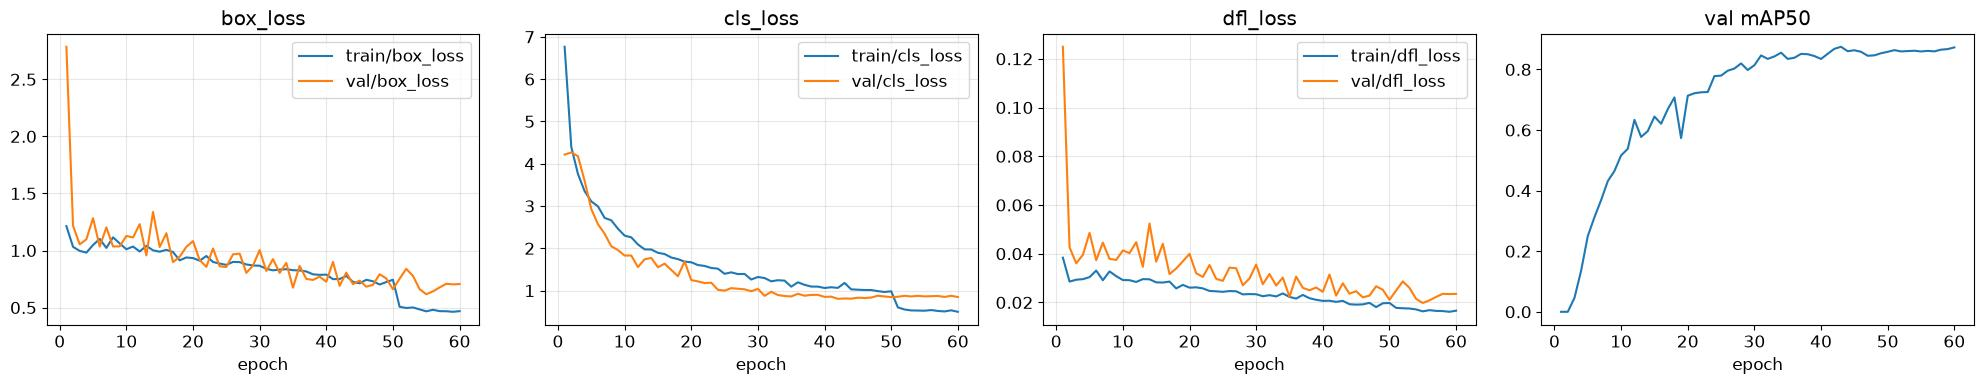

In [22]:
training_curves = read_results(run_dir)
loss_names = [k for k in training_curves if k.startswith('train/') and k.endswith('_loss')]
fig, axes = plt.subplots(1,len(loss_names)+1,figsize=(5*(len(loss_names)+1),4))
for ax, key in zip(axes,loss_names):
    ax.plot(training_curves['epoch'],training_curves[key],label=key)
    vk=key.replace('train/','val/')
    if vk in training_curves: ax.plot(training_curves['epoch'],training_curves[vk],label=vk)
    ax.set_title(key.split('/')[-1]); ax.legend(); ax.grid(alpha=.3)
map_key=next(k for k in training_curves if 'mAP50(' in k)
axes[-1].plot(training_curves['epoch'],training_curves[map_key]); axes[-1].set_title('val mAP50')
for ax in axes: ax.set_xlabel('epoch')
plt.tight_layout(); plt.show()

**Ответ:** Обучал до 60 эпох: AdamW, lr=0.001 с разогревом и cosine decay, batch=16 и imgsz=640 помещаются в 8 GB; исходные изображения 384×384, увеличение не добавляет деталей, но сохраняет стандартный режим предобученной модели. Дал умеренные повороты, масштабирование, цветовые изменения и горизонтальные отражения; вертикальный переворот для оборудования не нужен, mosaic отключается на последние 10 эпох, patience=20 ограничивает бесполезное ожидание. Реально прошло 60 эпох за 16.4 мин, лучший checkpoint по валидационному fitness оказался около эпохи 55; он выбирается по val, не по test. На графиках train/val loss в целом снижаются, устойчивого роста val loss при падающем train не видно; к концу mAP50 вышел примерно на плато 0.86–0.87, так что выбранного бюджета хватило для этого эксперимента, но оптимальность 60 эпох не доказана. Резкое снижение train loss после 50-й эпохи связано в том числе с отключением mosaic и более простыми примерами, а не только с улучшением весов. Лучший момент обучения выбирается по val-метрике, а не по пересечению train/val loss. В колонке dfl_loss здесь остаётся L1-компонента при reg_max=1, а не распределённый DFL — это видно в [BboxLoss версии 8.4.20](https://github.com/ultralytics/ultralytics/blob/v8.4.20/ultralytics/utils/loss.py).

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [23]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.20  Python-3.13.0 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


YOLO26n summary (fused): 122 layers, 2,377,176 parameters, 0 gradients, 5.2 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 116.052.9 MB/s, size: 13.3 KB)


val: Scanning C:\Users\arseni\all\code\deepLearning\labs\lab2\data\yolo\labels\val.cache... 120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 36.0Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 12% ━─────────── 1/8 2.1s/it 0.6s<14.4s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 2/8 1.1it/s 1.0s<5.5s

... (22 outputs left out)

                   all        120        139      0.791      0.753      0.819      0.695


Speed: 0.6ms preprocess, 7.1ms inference, 0.0ms loss, 0.2ms postprocess per image


Results saved to C:\Users\arseni\all\code\deepLearning\labs\lab2\runs_hw2\final\20261122_153400\final_test


validation: {'map50': 0.8593350227195368, 'map50_95': 0.7464846664757087, 'precision': 0.7125640305995807, 'recall': 0.8630959069402041, 'per_class': {'barbell': {'precision': 0.6897838203537049, 'recall': 0.6693514610611148, 'map50': 0.7160998650472333, 'map50_95': 0.5862966321782381}, 'cablemachine': {'precision': 0.8320261780923018, 'recall': 0.9, 'map50': 0.9719230769230767, 'map50_95': 0.8497476890925165}, 'dumbbell': {'precision': 0.5402656841889653, 'recall': 0.75, 'map50': 0.6476689998583856, 'map50_95': 0.500211495836813}, 'elliptical': {'precision': 0.5875351311224083, 'recall': 0.7272727272727273, 'map50': 0.6891122939560439, 'map50_95': 0.6015563261820416}, 'kettlebell': {'precision': 0.6625912788448309, 'recall': 0.9070888631604908, 'map50': 0.8304292508714527, 'map50_95': 0.7184006890217931}, 'legpress': {'precision': 0.7414043387566759, 'recall': 0.8621790905293739, 'map50': 0.9164285714285714, 'map50_95': 0.79656987012987}, 'smithmachine': {'precision': 0.80194070022919

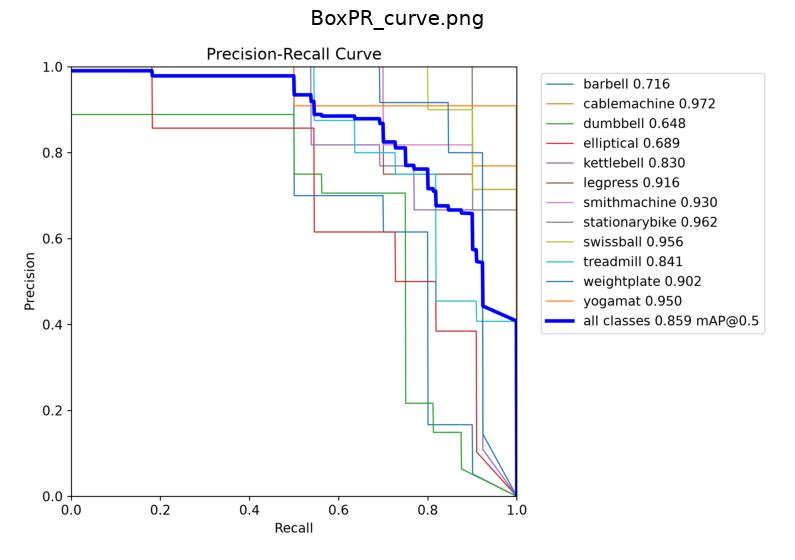

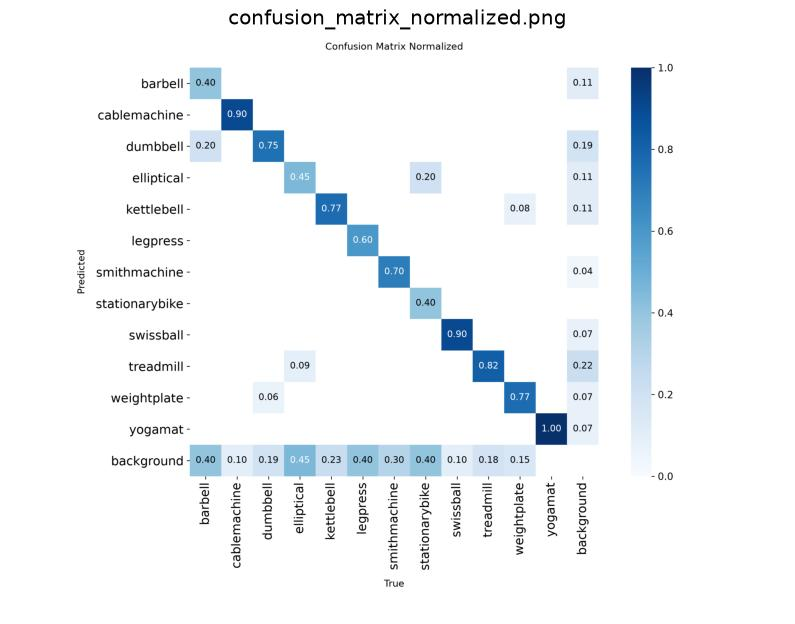

In [24]:
def summarize_metrics(result):
    per_class = {}
    for row, cls in enumerate(result.box.ap_class_index):
        p,r,ap50,ap = result.box.class_result(row)
        per_class[CLASSES[int(cls)]] = dict(precision=float(p), recall=float(r), map50=float(ap50), map50_95=float(ap))
    return dict(map50=float(result.box.map50), map50_95=float(result.box.map),
                precision=float(result.box.mp), recall=float(result.box.mr), per_class=per_class)

VAL_RESULT = val_metrics(best,'val','final_val')
VAL_FINAL = summarize_metrics(VAL_RESULT)
TEST_RESULT = val_metrics(best,FINAL_SPLIT,'final_test') if FINAL_SPLIT!='val' else VAL_RESULT
FINAL = summarize_metrics(TEST_RESULT)
final_predictions = predict_records(best,records[FINAL_SPLIT],conf=.001)
manual_map50, manual_aps = evaluate_map50(final_predictions,records[FINAL_SPLIT],len(CLASSES))
FINAL['manual_map50'] = manual_map50
print('validation:',VAL_FINAL)
print('final split:',FINAL_SPLIT,FINAL)
figures=[]
plot_dir=Path(VAL_RESULT.save_dir)
for pattern in ['*PR_curve.png','confusion_matrix_normalized.png']:
    figures += sorted(plot_dir.glob(pattern))
for file in figures:
    fig,ax=plt.subplots(figsize=(10,8)); ax.imshow(plt.imread(file)); ax.axis('off'); ax.set_title(file.name); plt.show()

In [25]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': 0.8186,
 'map50_95': 0.6946,
 'precision': 0.7913,
 'recall': 0.7532,
 'manual_map50': 0.8017}

**Ответ:** Лучшие веса дали val mAP50=0.859, mAP50-95=0.746; на test — 0.819 и 0.695, precision=0.791, recall=0.753. Эти P/R — усреднение по классам в точке максимального сглаженного F1 у Ultralytics, а не обязательно при conf=0.25; слабее на test вышли stationarybike (AP50=0.695), kettlebell (AP50=0.700), dumbbell (AP50=0.706), при небольшом числе примеров похожие рамы и отдельные части оборудования легко перепутать, а не все различия можно объяснить размером бокса. В confusion matrix по горизонтали истинный класс, по вертикали предсказанный: строка background показывает пропуски, столбец background — лишние детекции; mAP50-95 строже к точности рамок, потому что усредняет IoU от 0.5 до 0.95. Готовая функция из условия дала test mAP50=0.802 против 0.819: у неё all-point интегрирование вместо 101 точки, а также другой greedy matching в спорных случаях, поэтому полного совпадения не ожидаю. На val матрица показывает, например, barbell → dumbbell и stationarybike → elliptical (по 0.20 соответствующего истинного класса); в этой версии сама confusion matrix использует conf=0.25 и IoU=0.45 по умолчанию, поэтому её числа не обязаны совпадать с нашим разбором при IoU=0.5 или с P/R в точке max-F1.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [26]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # low threshold only for the FAST_MODE code check
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4)
    b = np.asarray(b, dtype=np.float64).reshape(-1, 4)
    intersection_wh = np.maximum(np.minimum(a[:, None, 2:], b[None, :, 2:])
                                 - np.maximum(a[:, None, :2], b[None, :, :2]), 0)
    intersection = intersection_wh.prod(axis=-1)
    area_a = np.maximum(a[:, 2:] - a[:, :2], 0).prod(axis=-1)
    area_b = np.maximum(b[:, 2:] - b[:, :2], 0).prod(axis=-1)
    union = area_a[:, None] + area_b[None, :] - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    pred_labels = np.asarray(pred['labels']).reshape(-1)
    gt_labels = np.asarray(gt['labels']).reshape(-1)
    scores = np.asarray(pred['scores'], dtype=float).reshape(-1)
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    categories = ['background'] * len(pred_labels)
    matched = np.zeros(len(gt_labels), dtype=bool)
    associated = np.zeros(len(gt_labels), dtype=bool)
    for i in np.argsort(-scores, kind='stable'):
        same_class = gt_labels == pred_labels[i]
        # Only a true positive consumes a GT for subsequent matching.
        candidates = np.flatnonzero(same_class & ~matched & (ious[i] >= iou_hit))
        category = 'tp'
        if not len(candidates):
            candidates = np.flatnonzero(~same_class & (ious[i] >= iou_hit))
            category = 'class'
        if not len(candidates):
            candidates = np.flatnonzero(same_class & ~matched & (ious[i] >= iou_loc)
                                        & (ious[i] < iou_hit))
            category = 'localization'
        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            categories[i] = category
            associated[j] = True
            if category == 'tp':
                matched[j] = True
    return categories, np.flatnonzero(~associated).tolist()

In [27]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


Ошибки на val, conf= 0.25 {'tp': 104, 'class': 11, 'localization': 2, 'background': 19, 'missed': 22}
По классам: {'barbell': {'tp': 5, 'class': 0, 'localization': 0, 'background': 2, 'missed': 4}, 'cablemachine': {'tp': 10, 'class': 0, 'localization': 0, 'background': 1, 'missed': 0}, 'dumbbell': {'tp': 11, 'class': 3, 'localization': 1, 'background': 3, 'missed': 4}, 'elliptical': {'tp': 7, 'class': 2, 'localization': 0, 'background': 2, 'missed': 2}, 'kettlebell': {'tp': 10, 'class': 0, 'localization': 0, 'background': 1, 'missed': 3}, 'legpress': {'tp': 6, 'class': 3, 'localization': 0, 'background': 1, 'missed': 4}, 'smithmachine': {'tp': 10, 'class': 0, 'localization': 0, 'background': 1, 'missed': 0}, 'stationarybike': {'tp': 5, 'class': 0, 'localization': 0, 'background': 0, 'missed': 4}, 'swissball': {'tp': 9, 'class': 1, 'localization': 0, 'background': 1, 'missed': 0}, 'treadmill': {'tp': 10, 'class': 0, 'localization': 0, 'background': 4, 'missed': 0}, 'weightplate': {'tp':

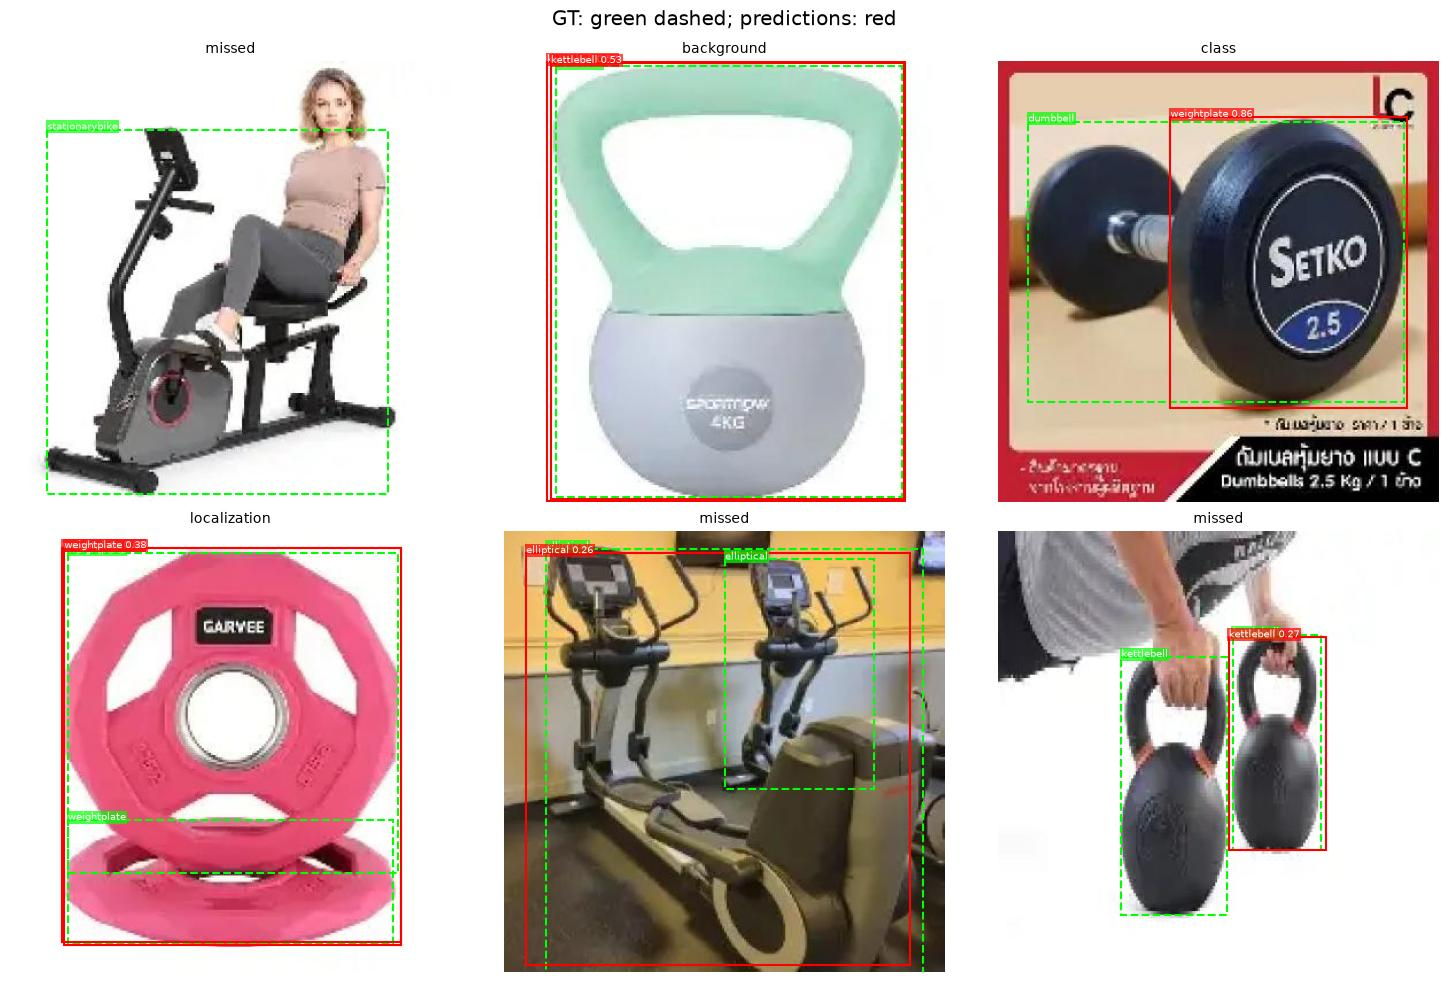

In [28]:
error_predictions=predict_records(best,records['val'],conf=CONF_ERRORS)
ERRORS={k:0 for k in ERROR_TYPES}
ERROR_BREAKDOWN={name:{k:0 for k in ERROR_TYPES} for name in CLASSES}
error_examples=[]
for r,p in zip(records['val'],error_predictions):
    categories,missed=categorize_predictions(p,r)
    for i,category in enumerate(categories):
        ERRORS[category]+=1
        ERROR_BREAKDOWN[CLASSES[int(p['labels'][i])]][category]+=1
    for i in missed:
        ERRORS['missed']+=1
        ERROR_BREAKDOWN[CLASSES[int(r['labels'][i])]]['missed']+=1
    present=set(categories)-{'tp'}
    if missed: present.add('missed')
    if present: error_examples.append((r,p,present))
print('Ошибки на val, conf=',CONF_ERRORS,ERRORS)
print('По классам:',ERROR_BREAKDOWN)
error_total=sum(v for k,v in ERRORS.items() if k!='tp')
ERROR_SHARES={k:v/max(1,error_total) for k,v in ERRORS.items() if k!='tp'}
print('Доли среди ошибок:',ERROR_SHARES)
chosen=[]; shown=set()
for example in error_examples:
    if example[2]-shown:
        chosen.append(example); shown |= example[2]
for example in error_examples:
    if len(chosen)>=6: break
    if not any(example[0]['image']==x[0]['image'] for x in chosen): chosen.append(example)
while len(chosen)<6:
    r=records['val'][len(chosen)]
    chosen.append((r,error_predictions[len(chosen)],{'no error at this threshold'}))
fig,axes=plt.subplots(2,3,figsize=(15,10))
for ax,(r,p,types) in zip(axes.flat,chosen[:6]):
    draw_boxes(ax,Image.open(r['image']),r['boxes'],r['labels'],CLASSES,color='lime',linestyle='--')
    draw_boxes(ax,None,p['boxes'],p['labels'],CLASSES,p['scores'],color='red',title=', '.join(sorted(types)))
plt.suptitle('GT: green dashed; predictions: red'); plt.tight_layout(); plt.show()

**Ответ:** На val при conf=0.25 получилось TP=104, class=11, localization=2, background=19, missed=22; среди ошибок больше всего missed (40.7%). Категории считаются своим кодом по контракту задания: class/localization привязываются к объекту и могут исключать его из missed, поэтому missed здесь не равен всем FN из обычной метрики recall. На рисунках зелёные пунктирные боксы — GT, красные — модель; примеры нужно отличать от доказательства идеальной разметки, особенно когда видны похожие предметы или неполные границы. Для улучшения я бы сначала собрал разнообразные реальные сцены и дополнительные примеры проблемных классов, проверил спорную разметку, а порог уверенности подбирал по val под цену пропуска и лишнего срабатывания. На конкретных примерах видны пропущенный велотренажёр с человеком, один пропуск из пары гирь, путаница гантели с блином и рамка сразу вокруг двух блинов вместо отдельных объектов — это в первую очередь ограничения модели, хотя спорные границы в разметке тоже стоит проверить.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [29]:
freeze_layers=len(arch.yaml['backbone'])
ablation_model,ablation_seconds,ablation_dir=train_yolo('frozen_backbone',freeze=freeze_layers,**TRAIN_ARGS)
ablation_best=YOLO(ablation_dir/'weights'/'best.pt')
ablation_val=ablation_best.val(data=str(DATA_YAML),split='val',imgsz=IMGSZ,batch=BATCH,device=DEVICE,workers=WORKERS,
                              project=str(RUNS.resolve()),name='ablation_val',exist_ok=True,verbose=False,plots=False)
ABLATION=dict(parameter='freeze',values=[0,freeze_layers],split='val',
              finetune=dict(**VAL_FINAL,seconds=RUN_TIMES['train'],epochs=len(training_curves['epoch'])),
              frozen=dict(**summarize_metrics(ablation_val),seconds=ablation_seconds,
                          epochs=len(read_results(ablation_dir)['epoch'])))
RUN_TIMES['ablation']=ablation_seconds
print(ABLATION)

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.20  Python-3.13.0 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data\yolo\data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=11, half=False, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=frozen_backbone, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=20, perspective=0.0, plots=True, pose=12.0, pretrained=True, profile=False, project=C:\Users\arseni\all\

Overriding model.yaml nc=80 with nc=12



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (1,979 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.6it/s 2.2s

                   all        120        134      0.818      0.687      0.788      0.681


Speed: 1.1ms preprocess, 8.3ms inference, 0.0ms loss, 0.2ms postprocess per image


{'parameter': 'freeze', 'values': [0, 11], 'split': 'val', 'finetune': {'map50': 0.8593350227195368, 'map50_95': 0.7464846664757087, 'precision': 0.7125640305995807, 'recall': 0.8630959069402041, 'per_class': {'barbell': {'precision': 0.6897838203537049, 'recall': 0.6693514610611148, 'map50': 0.7160998650472333, 'map50_95': 0.5862966321782381}, 'cablemachine': {'precision': 0.8320261780923018, 'recall': 0.9, 'map50': 0.9719230769230767, 'map50_95': 0.8497476890925165}, 'dumbbell': {'precision': 0.5402656841889653, 'recall': 0.75, 'map50': 0.6476689998583856, 'map50_95': 0.500211495836813}, 'elliptical': {'precision': 0.5875351311224083, 'recall': 0.7272727272727273, 'map50': 0.6891122939560439, 'map50_95': 0.6015563261820416}, 'kettlebell': {'precision': 0.6625912788448309, 'recall': 0.9070888631604908, 'map50': 0.8304292508714527, 'map50_95': 0.7184006890217931}, 'legpress': {'precision': 0.7414043387566759, 'recall': 0.8621790905293739, 'map50': 0.9164285714285714, 'map50_95': 0.7965

**Ответ:** Менял только freeze: 0 против 11 первых модулей, то есть всего backbone; оба запуска начались с одних COCO-весов и имели одинаковые настройки и бюджет до 60 эпох. Полное дообучение: val mAP50=0.859, mAP50-95=0.746, 16.4 мин (60 эпох); заморозка: 0.788, 0.681, 13.3 мин (60 эпох). Заморозка экономит вычисления на градиентах backbone, но ограничивает адаптацию признаков под спортивное оборудование; разницу качества оцениваю именно на одном val, а не сравнением разных сплитов. Один seed и маленький val не позволяют считать разницу универсальной: для следующего шага повторил бы сравнение на нескольких seed. В этом запуске разница mAP50-95 в пользу полного дообучения составила +0.065, а отношение времени полного к замороженному — 1.23; для итоговой модели оставляю полное дообучение, если важнее качество, чем эта экономия времени.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:** На test дообученный YOLO26n получил mAP50=0.819 и mAP50-95=0.695, простая эвристика — mAP50=0.218. COCO-модель без дообучения дала 0 по нашему словарю классов, поэтому её ноль нельзя трактовать как полное отсутствие детекций. Конвертация COCO → YOLO прошла обратную проверку с ошибкой меньше 0.001 пикселя. На val полное дообучение и заморозка backbone дали mAP50 0.859 и 0.788. В разборе ошибок при conf=0.25 основная категория — missed, поэтому одного итогового mAP недостаточно для понимания модели. Два бонуса показывают влияние искажений и порогов, но настройки выбирались только на val. Ограничения — один seed, 120 картинок в каждом контрольном сплите, неидеальная разметка и в основном каталожные фото; дальше я бы проверял новые реальные сцены из зала и добирал данные по слабым классам.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'bonus_metrics.json', 'BoxPR_curve.png', 'confusion_matrix_normalized.png', 'diagnostics.json', 'metrics.json', 'results.csv']


In [31]:
# Статистика данных и диагностика модели.
diagnostics=dict(model_info=MODEL_INFO, blocks=blocks, feature_shapes=feat_shapes,
                  cleaning=CLEANING, data_stats=DATA_STATS, exact_duplicates=EXACT_DUPLICATES,
                  roundtrip_max_error_px=max(roundtrip_errors), validation=VAL_FINAL,
                  error_shares=ERROR_SHARES, errors_by_class=ERROR_BREAKDOWN,
                  heuristic_feature_count=features.shape[1],
                  coco_predicted_counts=dict(Counter(coco_names[int(c)] for p in coco_preds_raw for c in p['labels'])))
(artifact_dir/'diagnostics.json').write_text(json.dumps(json_ready(diagnostics),ensure_ascii=False,indent=2),encoding='utf-8')
for file in figures:
    shutil.copy2(file,artifact_dir/file.name)


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [32]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** Бонус не выбирал; он отключён в BONUS_TASKS.

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [33]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** Бонус не выбирал; он отключён в BONUS_TASKS.

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

Ultralytics 8.4.20  Python-3.13.0 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


val: Fast image access  (ping: 0.00.0 ms, read: 1.70.2 MB/s, size: 19.4 KB)


val: Scanning C:\Users\arseni\all\code\deepLearning\labs\lab2\data\shifts\dark\labels\val.cache... 120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 33.6Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 12% ━─────────── 1/8 1.7s/it 0.5s<12.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 2/8 1.1it/s 0.9s<5.3s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 38% ━━━━──────── 3/8 1.5it/s 1.3s<3.3s

... (30 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.5it/s 2.3s

                   all        120        134      0.801      0.705      0.814      0.709


Speed: 0.4ms preprocess, 6.1ms inference, 0.0ms loss, 0.2ms postprocess per image


{'clean': {'map50': 0.8593350227195368, 'map50_95': 0.7464846664757087}, 'dark': {'map50': 0.8747355286091287, 'map50_95': 0.7568393675330181}, 'noise': {'map50': 0.37811445839476304, 'map50_95': 0.28193358546809727}, 'jpeg': {'map50': 0.8138686706645418, 'map50_95': 0.7092842978467061}}


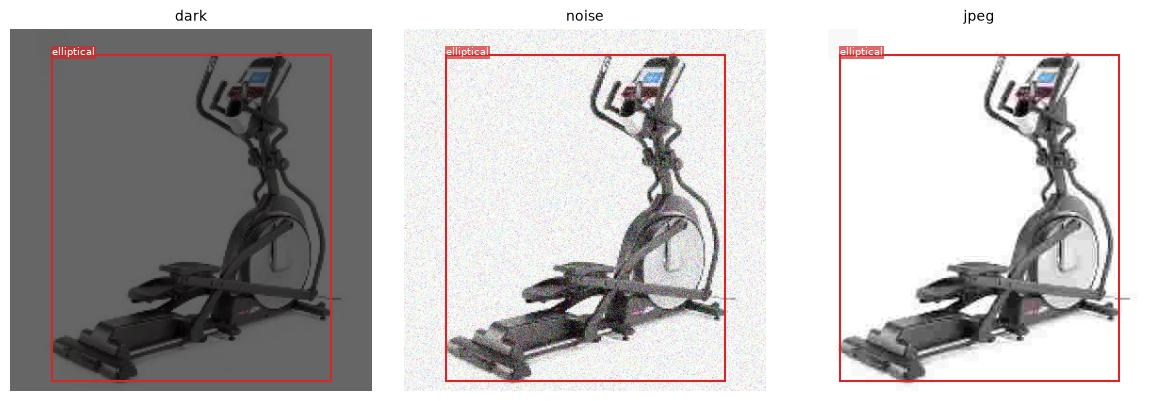

In [34]:
if '6.3' in BONUS_TASKS:
    def make_eval_yaml(recs, target):
        image_dir, label_dir = target/'images'/'val', target/'labels'/'val'
        image_dir.mkdir(parents=True,exist_ok=True); label_dir.mkdir(parents=True,exist_ok=True)
        for i,r in enumerate(recs):
            shutil.copy2(r['image'],image_dir/f'{i:06d}.jpg')
            (label_dir/f'{i:06d}.txt').write_text(to_yolo(r['boxes'],r['labels'],r['width'],r['height']),encoding='utf-8')
        yaml=target/'data.yaml'
        yaml.write_text('path: '+target.resolve().as_posix()+'\ntrain: images/val\nval: images/val\nnames:\n'+
                        ''.join(f'  {i}: {name}\n' for i,name in enumerate(CLASSES)),encoding='utf-8')
        return yaml

    shift_results={'clean':VAL_FINAL}
    shift_recipes={'dark':dict(brightness=.4),'noise':dict(std=.12),'jpeg':dict(quality=10)}
    rng=np.random.default_rng(SEED)
    preview_images=[]
    for shift,recipe in shift_recipes.items():
        target=DATA_ROOT/'shifts'/shift
        image_dir=target/'source'; image_dir.mkdir(parents=True,exist_ok=True)
        modified=[]
        for i,r in enumerate(records['val']):
            image=Image.open(r['image']).convert('RGB')
            array=np.asarray(image).astype(np.float32)/255
            if shift=='dark': array=array*recipe['brightness']
            elif shift=='noise': array=np.clip(array+rng.normal(0,recipe['std'],array.shape),0,1)
            output=Image.fromarray((array.clip(0,1)*255).round().astype(np.uint8))
            dest=image_dir/f'{i:06d}.jpg'
            output.save(dest,quality=recipe['quality'] if shift=='jpeg' else 95)
            modified.append(dict(r,image=dest))
        yaml=make_eval_yaml(modified,target)
        result=best.val(data=str(yaml),split='val',imgsz=IMGSZ,batch=BATCH,device=DEVICE,workers=WORKERS,
                        project=str(RUNS.resolve()),name='shift_'+shift,exist_ok=True,verbose=False,plots=False)
        shift_results[shift]=summarize_metrics(result)
        preview_images.append((shift,modified[0]))
    print({k:{m:v[m] for m in ['map50','map50_95']} for k,v in shift_results.items()})
    fig,axes=plt.subplots(1,3,figsize=(12,4))
    for ax,(name,r) in zip(axes,preview_images):
        draw_boxes(ax,Image.open(r['image']),r['boxes'],r['labels'],CLASSES,title=name)
    plt.tight_layout(); plt.show()


**Ответ:** На чистом val mAP50=0.859; после затемнения — 0.875, шума — 0.378, JPEG quality=10 — 0.814. Сильнее всего по mAP50 ударило noise; самые большие падения AP50 относительно чистых данных у swissball, stationarybike, barbell. Геометрия и разметка не менялись, модель не переобучалась на этих копиях; для устойчивости проверил бы соответствующие фотометрические аугментации при обучении и реальные примеры плохого освещения/сжатия, поскольку синтетические искажения не заменяют настоящий сдвиг домена. Для самого сильного искажения конкретная кандидатная аугментация — добавление гауссова и сенсорного шума; её пользу ещё нужно отдельно проверить на неизменном val. Затемнение здесь даже немного улучшило mAP50: ожидаемого падения нет, и это нормальный результат. На 120 каталожных фото изменение контраста может оказаться благоприятным, но одного такого опыта недостаточно, чтобы обещать улучшение на тёмных реальных сценах.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [35]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** Бонус не выбирал; он отключён в BONUS_TASKS.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

Ultralytics 8.4.20  Python-3.13.0 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


YOLO26n summary (fused): 122 layers, 2,377,176 parameters, 0 gradients, 5.2 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 25.26.5 MB/s, size: 11.9 KB)


val: Scanning C:\Users\arseni\all\code\deepLearning\labs\lab2\data\yolo\labels\val.cache... 120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 31.5Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 12% ━─────────── 1/8 1.3it/s 0.2s<5.6s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 2/8 2.1it/s 0.5s<2.9s

... (201 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.6it/s 1.7s

                   all        120        134      0.927       0.87       0.91      0.799


Speed: 0.4ms preprocess, 5.7ms inference, 0.0ms loss, 1.2ms postprocess per image


{'end2end': False, 'conf': 0.5, 'iou': 0.7, 'map50': 0.9098675050439754, 'map50_95': 0.7990946272075509, 'precision': 0.8914728682170543, 'recall': 0.8582089552238806, 'f1': 0.8745247148288975, 'tp': 115, 'fp': 14, 'fn': 19}


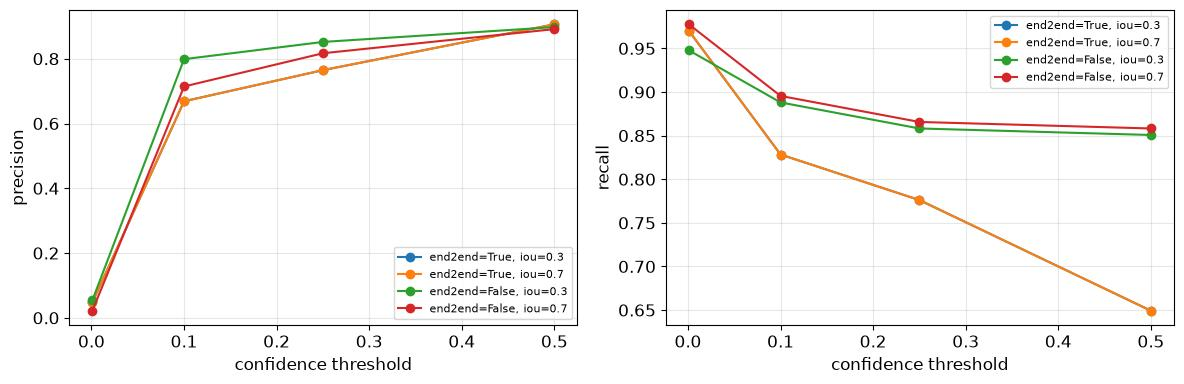

In [36]:
if '6.5' in BONUS_TASKS:
    def operating_metrics(predictions, truth):
        tp = sum(categorize_predictions(p,r)[0].count('tp') for p,r in zip(predictions,truth))
        n_pred = sum(len(p['labels']) for p in predictions)
        n_gt = sum(len(r['labels']) for r in truth)
        precision=tp/n_pred if n_pred else 0.
        recall=tp/n_gt if n_gt else 0.
        f1=2*precision*recall/(precision+recall) if precision+recall else 0.
        return dict(precision=precision,recall=recall,f1=f1,tp=tp,fp=n_pred-tp,fn=n_gt-tp)

    threshold_grid=[]
    for mode in [True,False]:
        # Свежий объект: fusion при end2end=True удаляет неиспользуемую one2many-ветку.
        detector=YOLO(run_dir/'weights'/'best.pt')
        for conf in [.001,.1,.25,.5]:
            for iou in [.3,.7]:
                result=detector.val(data=str(DATA_YAML),split='val',imgsz=IMGSZ,batch=BATCH,device=DEVICE,workers=WORKERS,
                                    project=str(RUNS.resolve()),name=f'grid_{int(mode)}_{conf}_{iou}',
                                    exist_ok=True,verbose=False,plots=False,conf=conf,iou=iou,end2end=mode)
                predictions=predict_records(detector,records['val'],conf=conf,iou=iou,end2end=mode)
                row=dict(end2end=mode,conf=conf,iou=iou,map50=float(result.box.map50),map50_95=float(result.box.map),
                         **operating_metrics(predictions,records['val']))
                threshold_grid.append(row)
                print(row)
        del detector
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for mode in [True,False]:
        for iou in [.3,.7]:
            rows=[r for r in threshold_grid if r['end2end']==mode and r['iou']==iou]
            label=f'end2end={mode}, iou={iou}'
            axes[0].plot([r['conf'] for r in rows],[r['precision'] for r in rows],'o-',label=label)
            axes[1].plot([r['conf'] for r in rows],[r['recall'] for r in rows],'o-',label=label)
    for ax,key in zip(axes,['precision','recall']):
        ax.set_xlabel('confidence threshold'); ax.set_ylabel(key); ax.grid(alpha=.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()


**Ответ:** Среди проверенных end-to-end вариантов максимум pooled F1 на val получился при conf=0.25: P=0.765, R=0.776, F1=0.770; это разумная стартовая настройка для каталога, если пропуски и лишние срабатывания одинаково нежелательны, но не универсальный оптимум. Эти P/R посчитаны из суммарных TP/FP/FN при фиксированном conf, поэтому отличаются от автоматической F1-точки Ultralytics в 4.2. mAP использует ранжирование по scores и при низком пороге может почти не меняться, но высокий conf отбрасывает правильные детекции, урезает recall и тоже снижает AP — здесь это видно в таблице. В end-to-end one2one NMS нет, поэтому iou=0.3/0.7 не должен менять детекции; в end2end=False включается one2many + NMS и порог IoU уже влияет на подавление перекрывающихся рамок. В нашей таблице максимальная разница mAP50/P/R между двумя IoU в end-to-end равна 0.000000, то есть отсутствие влияния проверено экспериментом. При одинаковом conf=0.001 ветка one2many + NMS с iou=0.3 дала mAP50=0.929 против 0.859 у one2one: на нашем val она заметно сильнее, хотя это не универсальный вывод о двух режимах. Если выбирать режим для дальнейшего применения по этой сетке, проверил бы end2end=False, conf=0.5, iou=0.7 (P=0.891, R=0.858, F1=0.875); основной test-результат в 4.2 относится к исходному end-to-end режиму, результаты разных режимов не смешиваю.

In [37]:
bonus_metrics = dict(bonus_tasks=sorted(BONUS_TASKS),fast_mode=FAST_MODE)
if '6.3' in BONUS_TASKS:
    bonus_metrics['6.3']=dict(recipes=shift_recipes,results=shift_results,split='val',n_images=len(records['val']))
if '6.5' in BONUS_TASKS:
    bonus_metrics['6.5']=dict(grid=threshold_grid,split='val',iou_match=.5,
                             precision_recall='pooled counts at fixed conf, not ultralytics max-F1 point')
(artifact_dir/'bonus_metrics.json').write_text(json.dumps(json_ready(bonus_metrics),ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
print('Сохранены бонусы:',sorted(BONUS_TASKS))

Сохранены бонусы: ['6.3', '6.5']
